# Homework 6

**Coverage:** Lectures 19–20: state-space models and Kalman filtering.

**Due:** Sunday, October 25, 2026, at 11:59 p.m. Eastern Time.

**Total:** 100 points.

## Instructions

- All simulation, filtering, and plotting code is provided. Run the code cells in order without changing their contents; enter your responses in the answer text cells. You are not expected to study the implementation or write code.
- Answer the seven lettered parts. Show the short calculation in 1(a); otherwise, two or three sentences or short bullet points per part are sufficient. No derivations or separate report are required.
- Submit a PDF of your completed notebook, including your name, answers, and the generated tables and figures.
- This notebook uses NumPy, SciPy, pandas, and Matplotlib, available in a standard Google Colab runtime. It does not need a data download or Google Drive access.

Relevant reading: [Filtering basics](https://predictivesciencelab.github.io/data-analytics-se/lecture19/reading-19.html), [Kalman filters](https://predictivesciencelab.github.io/data-analytics-se/lecture20/reading-20.html), and the [object-tracking example](https://predictivesciencelab.github.io/data-analytics-se/lecture20/hands-on-20.1.html).

## Student details

**First name:** Harishteja

**Last name:** Peddi

**Purdue email:** peddih@purdue.edu


## Problem 1: What does one measurement change? (20 points)

**Credit:** Course exercise using the scalar version of the update equations in [Lecture 20](https://predictivesciencelab.github.io/data-analytics-se/lecture20/reading-20.html).

Before receiving a new position measurement, our predicted position is Gaussian with mean $\mu^p=10$ mm and variance $V^p=4$ mm$^2$. The sensor reports $y=14$ mm. Its error is independent of the predicted position, Gaussian, and has mean zero and variance $R=4$ mm$^2$.

The scalar Kalman update is

$$
K=\frac{V^p}{V^p+R},\qquad
\mu=\mu^p+K(y-\mu^p),\qquad
V=(1-K)V^p.
$$

Here $K$ is the **Kalman gain**: the weight given to the difference between the new measurement and its prediction. The updated mean and variance are $\mu$ and $V$.

### (a) One update (10 points)

Find $K$, $\mu$, and $V$. Why does the updated mean lie halfway between the prediction and the measurement?


*Your answer:*

The Kalman gain is
$$
K = \frac{V_p}{V_p + R}
= \frac{4}{4 + 4}
= \boxed{0.5}.
$$

The updated mean is
$$
\mu = \mu_p + K(y - \mu_p)
= 10 + 0.5(14 - 10)
= \boxed{12\ \text{mm}}.
$$

The updated variance is
$$
V = (1 - K)V_p
= (1 - 0.5)(4)
= \boxed{2\ \text{mm}^2}.
$$

The updated mean lies halfway between the prediction and the measurement
because their variances are equal, $V_p = R$. Thus, both receive equal weight:
$$
\mu = (1 - K)\mu_p + Ky
= 0.5(10) + 0.5(14)
= 12\ \text{mm}.
$$

### (b) A less precise sensor (10 points)

Keep the same prediction and reported measurement, but suppose $R=16$ mm$^2$. Without doing another calculation, state whether $K$ increases or decreases, whether $\mu$ moves closer to 10 mm or 14 mm, and whether the updated variance is larger or smaller than in (a). Explain the connection.


*Your answer:*

When the measurement variance increases to $R = 16\ \text{mm}^2$:

- The Kalman gain $K$ **decreases**.
- The updated mean $\mu$ moves **closer to $10\ \text{mm}$**, the predicted mean.
- The updated variance is **larger than in part (a)**.

A larger measurement variance means the sensor is less precise, so the
measurement receives less weight and the prediction receives more weight.
Consequently, the updated mean shifts less toward the measurement, and
the measurement reduces our uncertainty by a smaller amount.

## Problem 2: Can a position sensor tell us the velocity? (45 points)

**Credit:** Course adaptation of the predict/update and state-uncertainty plots in the book's [object-tracking example](https://predictivesciencelab.github.io/data-analytics-se/lecture20/hands-on-20.1.html). The physical relation is the standard forced, damped oscillator; see [OpenStax, University Physics, Section 15.6](https://openstax.org/books/university-physics-volume-1/pages/15-6-forced-oscillations). The simulated experiment and questions are constructed for this assignment. The provided discretization uses SciPy's [matrix exponential](https://docs.scipy.org/doc/scipy/reference/generated/scipy.linalg.expm.html); you do not need to derive or implement it.

We observe a damped oscillator using a noisy position sensor. There is no velocity sensor. Ignoring disturbances for a moment, its position $q$ satisfies

$$
\ddot q+2\zeta\omega_0\dot q+\omega_0^2 q=u,
\qquad \omega_0=2\ \mathrm{rad/s},\quad \zeta=0.15.
$$

Here $\omega_0$ is the natural angular frequency, $\zeta$ is the damping ratio, and $u$ is a known acceleration input (force per unit mass). The simulator samples every $\Delta t=0.05$ s. The index $t$ counts these sampling times; plots show elapsed time in seconds. During step $t$, the input is held at $u_t=0.6\cos(1.2t\Delta t)$ m/s$^2$.

The state contains position and velocity, $v=\dot q$. We use the class notation

$$
\mathbf{x}_t=\begin{pmatrix}q_t\\v_t\end{pmatrix},\qquad
\mathbf{x}_{t+1}=\mathbf{A}\mathbf{x}_t+\mathbf{B}u_t+\mathbf{z}_t,\qquad
y_t=\mathbf{C}\mathbf{x}_t+w_t,\quad \mathbf{C}=\begin{pmatrix}1&0\end{pmatrix}.
$$

The supplied code computes $\mathbf{A}$ and $\mathbf{B}$ from the oscillator equation. **Process noise** $\mathbf{z}_t$ represents disturbances to the state between measurements. **Measurement noise** $w_t$ represents sensor error:

$$
\mathbf{z}_t\sim\mathcal{N}(\mathbf{0},\mathbf{Q}_{\mathrm{true}}),\qquad
\mathbf{Q}_{\mathrm{true}}=\begin{pmatrix}2\times10^{-5}&0\\0&5\times10^{-4}\end{pmatrix},
\qquad w_t\sim\mathcal{N}(0,R),\quad R=(0.04)^2.
$$

Position is in meters and velocity in meters per second, so the diagonal entries of $\mathbf{Q}_{\mathrm{true}}$ have units m$^2$ and (m/s)$^2$, respectively; $R$ has units m$^2$. These are discrete-time disturbances added once per step. All noise draws are independent across time, and the process and sensor noises are independent of one another and of the initial state.

**These are simulated data, not measurements from a physical experiment.** We fix the true initial position and velocity at $(0.35\ \mathrm{m},-0.20\ \mathrm{m/s})$. The filter is not given this true state. Before the first measurement, it uses a Gaussian prior with mean $\mathbf{0}$ and covariance $\operatorname{diag}(0.25,0.25)$ in the corresponding squared units. It incorporates the measurement at time zero, then alternates prediction and update. It never uses future measurements or the true trajectory to compute its estimates.

### (a) Two kinds of noise (10 points)

A physical disturbance briefly changes the oscillator's velocity. Separately, the position sensor produces a bad reading without disturbing the oscillator. Which noise term represents each effect? Which effect can change future true positions, and why?


*Your answer:*

A physical disturbance that changes the oscillator's velocity is represented
by the **process noise** $z_t$, specifically its velocity component.
It changes the true state of the oscillator. Since velocity determines
how position evolves, this disturbance can change future true positions.

A bad position reading is represented by the **measurement noise** $w_t$.
It changes the reported measurement $y_t$ but does not change the oscillator's
true position or velocity. Therefore, it does not affect future true positions,
although it can affect the filter's estimates.

### Run the experiment

Run the following supplied cells. Keep the fixed random seeds. The first plot shows the true state, measurements, and filtered estimates. The filter uses the correct process and measurement covariances in this part. The true state is revealed only for evaluating the filter.


In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import expm
from IPython.display import display
from IPython import get_ipython

# Display figures inside the notebook, including in a fresh noninteractive kernel.
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")

plt.rcParams.update({"font.size": 11, "figure.dpi": 110})

omega0, zeta, dt = 2.0, 0.15, 0.05
time_s = np.arange(0.0, 20.0 + dt / 2, dt)
u = 0.6 * np.cos(1.2 * time_s[:-1])

# Exact noisefree discretization for an input held constant within each step.
continuous_A = np.array([[0.0, 1.0], [-omega0**2, -2*zeta*omega0]])
augmented = np.zeros((3, 3))
augmented[:2, :2] = continuous_A
augmented[1, 2] = 1.0
discrete = expm(augmented * dt)
A, B = discrete[:2, :2], discrete[:2, 2]
C = np.array([1.0, 0.0])
Q_true = np.diag([2e-5, 5e-4])
R = 0.04**2
prior_mu = np.zeros(2)
prior_V = np.diag([0.25, 0.25])

process_rng = np.random.default_rng(5390601)
sensor_rng = np.random.default_rng(5390602)
x_true = np.empty((len(time_s), 2))
x_true[0] = [0.35, -0.20]
for t in range(len(time_s) - 1):
    z = process_rng.multivariate_normal(np.zeros(2), Q_true)
    x_true[t + 1] = A @ x_true[t] + B * u[t] + z
y = x_true @ C + sensor_rng.normal(0, np.sqrt(R), len(time_s))
print(f"Generated {len(y)} position measurements over 20 seconds.")


Generated 401 position measurements over 20 seconds.


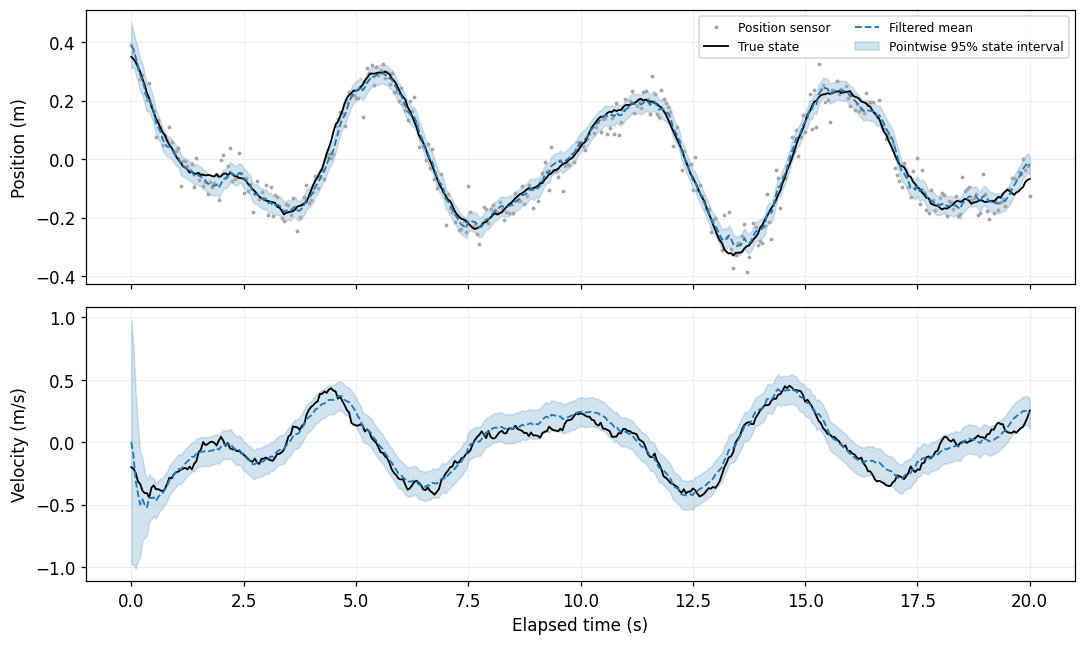

In [10]:
def kalman_filter(y, u, A, B, C, Q, R, prior_mu, prior_V):
    # The function receives observations and model assumptions, never x_true.
    mu, V = prior_mu.copy(), prior_V.copy()
    means, covariances = [], []
    for t, observation in enumerate(y):
        if t > 0:
            mu = A @ mu + B * u[t - 1]
            V = A @ V @ A.T + Q
        K = V @ C / (C @ V @ C + R)
        mu = mu + K * (observation - C @ mu)
        # A numerically stable form of the covariance update; no derivation needed.
        I_minus_KC = np.eye(2) - np.outer(K, C)
        V = I_minus_KC @ V @ I_minus_KC.T + R * np.outer(K, K)
        means.append(mu.copy())
        covariances.append(V.copy())
    return np.array(means), np.array(covariances)


def run_filter(Q):
    mu, V = kalman_filter(y, u, A, B, C, Q, R, prior_mu, prior_V)
    sd = np.sqrt(np.diagonal(V, axis1=1, axis2=2))
    return {"mu": mu, "V": V, "sd": sd}


nominal = run_filter(Q_true)
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for j, ax in enumerate(axes):
    if j == 0:
        ax.plot(time_s, y, ".", color="0.65", ms=3, label="Position sensor")
    ax.plot(time_s, x_true[:, j], color="black", lw=1.2, label="True state")
    ax.plot(time_s, nominal["mu"][:, j], color="tab:blue", ls="--", lw=1.2,
            label="Filtered mean")
    ax.fill_between(time_s, nominal["mu"][:, j] - 1.96*nominal["sd"][:, j],
                    nominal["mu"][:, j] + 1.96*nominal["sd"][:, j],
                    color="tab:blue", alpha=.2, label="Pointwise 95% state interval")
    ax.set_ylabel(["Position (m)", "Velocity (m/s)"][j])
    ax.grid(alpha=.2)
axes[0].legend(loc="upper right", fontsize=8, ncol=2)
axes[1].set_xlabel("Elapsed time (s)")
fig.tight_layout()
plt.show()


### (b) Estimating an unmeasured quantity (20 points)

The **root mean squared error (RMSE)** is the square root of the average squared estimation error over the sampled times. It has the same units as the estimated quantity; smaller is better. The next cell computes it using the known simulated truth.

Compare the position RMSE of the raw measurements with that of the filter. Use the velocity plot to describe whether the estimate follows the true velocity, including any initial adjustment. How can a position-only sensor help estimate velocity? Explain in terms of the connection between position and velocity over time; no matrix calculation is needed.


In [11]:
position_sensor_rmse = np.sqrt(np.mean((y - x_true[:, 0])**2))
nominal_rmse = np.sqrt(np.mean((nominal["mu"] - x_true)**2, axis=0))
baseline_table = pd.DataFrame({
    "Estimate": ["Raw position measurement", "Filtered position", "Filtered velocity"],
    "RMSE": [position_sensor_rmse, nominal_rmse[0], nominal_rmse[1]],
    "Units": ["m", "m", "m/s"],
})
display(baseline_table.round(4))


,Estimate,RMSE,Units
0,Raw position measurement,0.0411,m
1,Filtered position,0.0179,m
2,Filtered velocity,0.0574,m/s


*Your answer:*

The position RMSE of the raw measurements is approximately
$0.0411\ \text{m}$, while the filtered position RMSE is approximately
$0.0179\ \text{m}$. Thus, filtering reduces the position RMSE by about
$56\%$ by combining the noisy measurements with the model prediction.

The estimated velocity generally follows the oscillations of the true
velocity, with some deviations due to noise. Initially, the estimated
velocity is $0\ \text{m/s}$, whereas the true initial velocity is
$-0.20\ \text{m/s}$. As successive position measurements arrive, the
velocity estimate adjusts toward the true velocity, with some initial
overshoot.

A position-only sensor helps estimate velocity because velocity is the
rate of change of position:
$$
v = \frac{dq}{dt}.
$$
Successive position measurements provide information about how quickly
and in which direction the oscillator is moving. The filter combines
this information with the oscillator's dynamics to estimate velocity,
even though velocity is not measured directly.

### (c) What is inside the shaded band? (15 points)

At time $t$, the Kalman filter represents the state, given all position measurements observed so far, by a Gaussian with mean $\boldsymbol{\mu}_t$ and covariance $\mathbf{V}_t$. For component $j$ (position or velocity), the plot uses

$$
\mu_{t,j}\ \pm\ 1.96\sqrt{V_{t,jj}}.
$$

This is a **pointwise, marginal 95% state credible interval**: pointwise means one specified time; marginal means one state component considered separately. The probability statement is conditional on the assumed model, including its noise covariances and initial-state prior.

Explain its meaning for position at one fixed time. Does it assign 95% probability to the entire position trajectory lying inside the band? Is it an interval for a new noisy sensor reading? Briefly explain both distinctions.


*Your answer:*

At one fixed time $t$, the interval
$$
\mu_{t,q} \pm 1.96\sqrt{V_{t,qq}}
$$
contains the true position $q_t$ with approximately $95\%$ posterior
probability, given all position measurements observed up to that time
and the assumed model, noise covariances, and initial-state prior.

This does **not** assign $95\%$ probability to the entire position
trajectory lying inside the band. The probability statement applies
separately at each fixed time, rather than simultaneously at all times.

It is also **not** an interval for a new noisy sensor reading.
The shaded band describes uncertainty in the true position.
A new independent sensor reading at the same time includes additional
measurement noise, so its predictive interval would be
$$
\mu_{t,q} \pm 1.96\sqrt{V_{t,qq}+R},
$$
which is wider than the state credible interval.

## Problem 3: A confident filter is not always a good filter (35 points)

**Credit:** Course-designed noise-misspecification experiment using the Kalman-filter model in [Lecture 20](https://predictivesciencelab.github.io/data-analytics-se/lecture20/reading-20.html) and the oscillator simulator in Problem 2.

An engineer rarely knows the process-noise covariance exactly. Reuse the **same true trajectory and the same measurements**, but give the filter three different assumptions:

$$
\mathbf{Q}=0.05\mathbf{Q}_{\mathrm{true}},\qquad
\mathbf{Q}=\mathbf{Q}_{\mathrm{true}},\qquad
\mathbf{Q}=20\mathbf{Q}_{\mathrm{true}}.
$$

Everything else, including $R$ and the initial-state prior, stays unchanged. **Low**, **nominal**, and **high** refer only to the filter's assumed process noise, not to a change in the physical experiment.

The table reports RMSE, the average posterior standard deviation (**mean SD**), and the fraction of sampled times at which the true state lies in the corresponding 95% interval (**inside band**). The last quantity describes this one trajectory; correlated times are not independent repetitions of an experiment. It is not a proof of calibration, meaning agreement between probability statements and repeated-experiment frequencies.


,Assumed Q,Quantity,RMSE,Mean SD,Inside band (%)
0,Low,Position (m),0.0272,0.0090,45.1
1,Low,Velocity (m/s),0.0641,0.0235,43.6
2,Nominal,Position (m),0.0179,0.0174,93.8
3,Nominal,Velocity (m/s),0.0574,0.0637,95.5
4,High,Position (m),0.0258,0.0279,96.3
5,High,Velocity (m/s),0.0847,0.2237,100.0


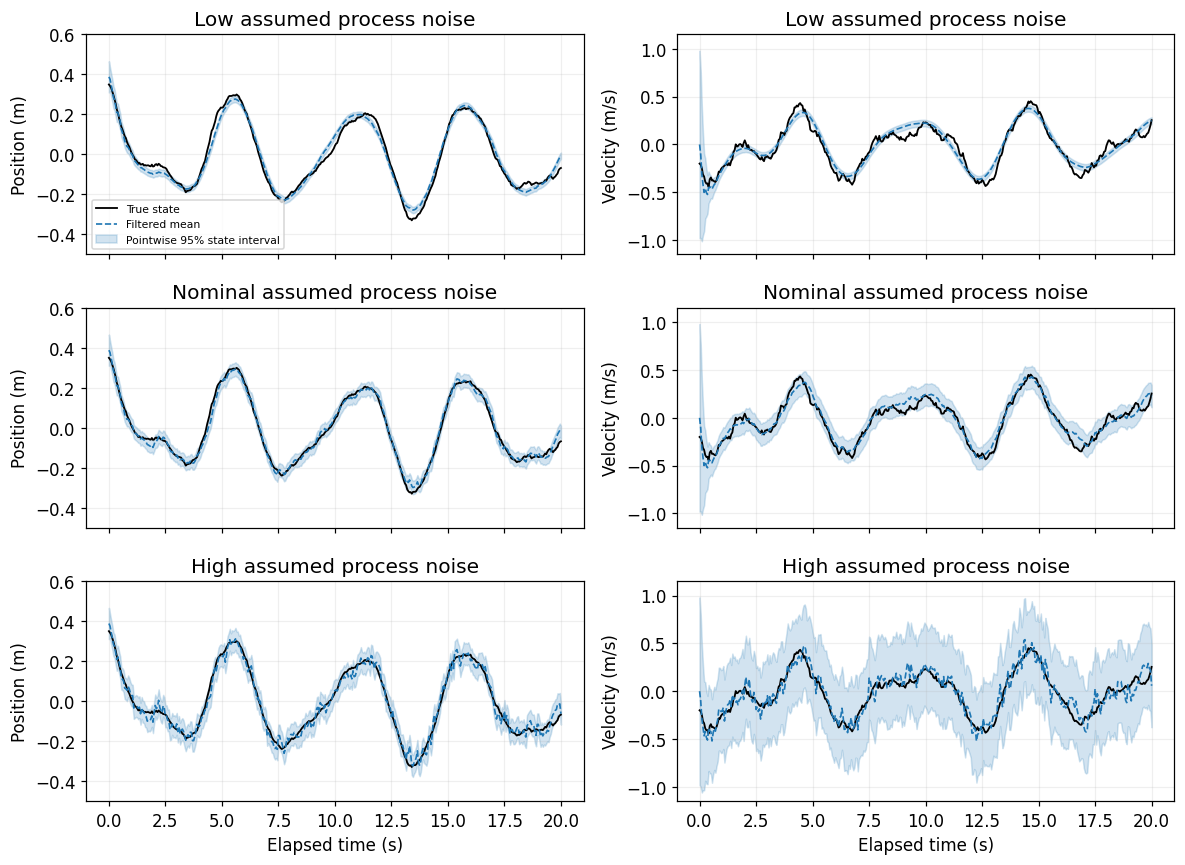

In [12]:
factors = {"Low": 0.05, "Nominal": 1.0, "High": 20.0}
runs = {name: run_filter(factor * Q_true) for name, factor in factors.items()}
rows = []
for name, result in runs.items():
    error = result["mu"] - x_true
    rmse = np.sqrt(np.mean(error**2, axis=0))
    mean_sd = result["sd"].mean(axis=0)
    inside = np.mean(np.abs(error) <= 1.96*result["sd"], axis=0)
    for j, quantity in enumerate(["Position (m)", "Velocity (m/s)"]):
        rows.append({"Assumed Q": name, "Quantity": quantity,
                     "RMSE": rmse[j], "Mean SD": mean_sd[j],
                     "Inside band (%)": 100*inside[j]})
comparison = pd.DataFrame(rows)
display(comparison.round({"RMSE": 4, "Mean SD": 4, "Inside band (%)": 1}))

fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharex=True)
for i, (name, result) in enumerate(runs.items()):
    for j in range(2):
        ax = axes[i, j]
        ax.plot(time_s, x_true[:, j], color="black", lw=1.2, label="True state")
        ax.plot(time_s, result["mu"][:, j], color="tab:blue", ls="--", lw=1.1,
                label="Filtered mean")
        ax.fill_between(time_s, result["mu"][:, j] - 1.96*result["sd"][:, j],
                        result["mu"][:, j] + 1.96*result["sd"][:, j],
                        color="tab:blue", alpha=.2, label="Pointwise 95% state interval")
        ax.set_title(f"{name} assumed process noise")
        ax.set_ylabel(["Position (m)", "Velocity (m/s)"][j])
        ax.grid(alpha=.2)
        # Hold the vertical scale fixed within each column for a fair comparison.
        ax.set_ylim([(-0.5, 0.6), (-1.15, 1.15)][j])
axes[0, 0].legend(fontsize=7, loc="lower left")
for ax in axes[-1]:
    ax.set_xlabel("Elapsed time (s)")
fig.tight_layout()
plt.show()


### (a) Error versus reported uncertainty (20 points)

Which assumption gives the smallest RMSE for position and for velocity in this experiment? Which gives the narrowest intervals? Use one numerical comparison from the table to explain why the low-noise filter is overconfident. Why does assuming less process noise lead the filter to report less uncertainty?


*Your answer:*

The **nominal assumption**, $Q=Q_{\mathrm{true}}$, gives the smallest
RMSE for both position ($0.0179\ \text{m}$) and velocity
($0.0574\ \text{m/s}$) in this experiment.

The **low-noise assumption**, $Q=0.05Q_{\mathrm{true}}$, gives the
narrowest intervals because it has the smallest posterior standard
deviations.

For example, the low-noise filter has a position RMSE of
$0.0272\ \text{m}$ but a mean posterior SD of only $0.0090\ \text{m}$.
Its position intervals contain the true position at only $45.1\%$
of the sampled times. This indicates overconfidence: the reported
uncertainty is too small relative to the actual estimation errors
in this experiment.

During prediction, the covariance is updated as
$$
V_{t+1}^{p}=A V_t A^\mathsf{T}+Q.
$$
Assuming a smaller $Q$ adds less uncertainty at each prediction step.
The filter therefore trusts the model more and reports smaller
posterior uncertainty, even though the actual disturbances have
not become smaller.

### (b) Back in the laboratory (15 points)

Suppose we now have only the position-sensor records from a real oscillator: there is no independent position or velocity reference. Could we compute the same true-state RMSE and inside-band fractions? An engineer proposes choosing the filter with the smoothest curve and narrowest intervals. Is that sufficient evidence that the estimates are accurate? Use the simulation to support your answer. You do not need to propose a new model-selection method.


*Your answer:*

No. Without an independent reference for the true position and velocity,
we cannot compute the same true-state RMSE or inside-band fractions.
Both require the true state. The sensor records contain measurement noise,
so they cannot be treated as the true position, and they do not directly
measure velocity.

Choosing the smoothest curve and narrowest intervals is not sufficient
evidence of accuracy. Smoothness can result from trusting the model too
strongly, while narrow intervals reflect the filter's assumed uncertainty.

The simulation demonstrates this: the low-noise filter gives the narrowest
intervals, but its position RMSE is $0.0272\ \text{m}$, compared with
$0.0179\ \text{m}$ for the nominal filter. Its position intervals contain
the truth at only $45.1\%$ of sampled times. Thus, a filter can appear
smooth and confident while producing less accurate estimates and
understating its uncertainty.